# Wealth plan: the Han family (Monte Carlo model)
**Stephanie Kim** · [Case study page](https://stephaniekim62-cpu.github.io/projects/wealth-plan.html)

The model behind the case study. The Han family is **fictional**, and its balance sheet is invented. Expected returns come from J.P. Morgan's 2027 Long-Term Capital Market Assumptions (as reported by WealthBriefing, Oct 2026). The skeptic case uses Vanguard's 10-year ranges. Volatilities and correlations are my own assumptions.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
assets = ["US large cap","Non-US developed","EM equity","US interm. Treasuries","US IG credit","US high yield",
          "Private equity","US core real estate","Hedge funds","Infrastructure","Cash"]
jpm  = np.array([7.5,7.3,7.1,4.6,6.1,6.7,9.8,8.1,6.7,7.1,3.3]) / 100   # compound returns; non-US dev & cash are my assumptions
skep = np.array([4.9,5.9,5.9,4.3,4.5,5.4,7.0,6.0,5.0,5.5,3.0]) / 100
vol  = np.array([16,17,21,5,7,9,20,11,7,10,0.5]) / 100
w    = np.array([28,12,5,10,15,4,8,6,6,3,3]) / 100
C = np.eye(11)
def s(i, j, v): C[i, j] = C[j, i] = v
s(0,1,.85); s(0,2,.72); s(1,2,.80)
for e in [0,1,2]:
    for j, v in zip(range(3,11), [-.05,.35,.70,.75,.45,.75,.60,0]): s(e, j, v)
for (i,j,v) in [(3,4,.70),(3,5,.15),(4,5,.55),(3,6,-.05),(4,6,.30),(5,6,.65),(3,7,.10),(4,7,.30),(5,7,.45),(6,7,.55),
                (3,8,0),(4,8,.40),(5,8,.70),(6,8,.65),(7,8,.40),(3,9,.25),(4,9,.45),(5,9,.55),(6,9,.55),(7,9,.65),(8,9,.50),(3,10,.1)]: s(i,j,v)
assert np.all(np.linalg.eigvalsh(C) > 0)
def port_stats(g):
    arith = w @ (g + vol**2 / 2); var = w @ (np.outer(vol, vol) * C) @ w
    return arith - var / 2, np.sqrt(var)      # compound return, volatility
pd.DataFrame({"J.P. Morgan 2027": port_stats(jpm), "Skeptic": port_stats(skep)}, index=["Compound return", "Volatility"]).round(4)

,J.P. Morgan 2027,Skeptic
Compound return,0.0738,0.0559
Volatility,0.1014,0.1014


## Concentrated alternative
49% employer stock (35% volatility, 0.6 correlation with US large cap, market-average expected return + 1.5 pts for higher beta), the rest in a 60/30/10 mix of US large cap, Treasuries and cash.

In [2]:
def conc_stats(g):
    v = np.array([.35,.16,.05,.005]); ww = np.array([.49,.306,.153,.051])
    aLC = g[0] + .16**2/2
    a = np.array([aLC + .015, aLC, g[3] + .05**2/2, g[10]])
    Cc = np.array([[1,.6,-.05,0],[.6,1,-.05,0],[-.05,-.05,1,.1],[0,0,.1,1]])
    var = ww @ (np.outer(v, v) * Cc) @ ww
    return ww @ a - var / 2, np.sqrt(var)
conc_stats(jpm)

(np.float64(0.06526323731250001), np.float64(0.20439086421608965))

## Monte Carlo: ages 54–95
Saves $300K/yr until retiring at 62, then spends $480K/yr after tax (grossed up at a 20% tax rate), inflation 2.5%, $80K/yr Social Security from 67. The proposed portfolio starts at $10.97M (after the DAF gift and ~$0.63M sell-down tax); the concentrated one at $12.2M.

In [3]:
def monte_carlo(g, sig, start, spend=480e3, retire=62, sims=10_000, seed=7):
    rng = np.random.default_rng(seed); ages = np.arange(54, 96); W = np.full(sims, start); alive = [1.0]
    for t, age in enumerate(ages):
        infl = 1.025 ** t
        flow = 300e3 * infl if age < retire else -(spend / .8 - (80e3 / .8 if age >= 67 else 0)) * infl
        W = np.maximum(W * np.exp(np.log(1 + g) + sig * rng.standard_normal(sims)) + flow, 0)
        alive.append((W > 0).mean())
    return np.array(alive)
res = {}
for name, g in [("J.P. Morgan 2027", jpm), ("Skeptic", skep)]:
    res[f"Proposed · {name}"] = monte_carlo(*port_stats(g), 10.97e6)
    res[f"Concentrated · {name}"] = monte_carlo(*conc_stats(g), 12.2e6)
pd.Series({k: v[-1] for k, v in res.items()}, name="Plan still funded at 95").map("{:.0%}".format)

Proposed · J.P. Morgan 2027        97%
Concentrated · J.P. Morgan 2027    78%
Proposed · Skeptic                 84%
Concentrated · Skeptic             59%
Name: Plan still funded at 95, dtype: str

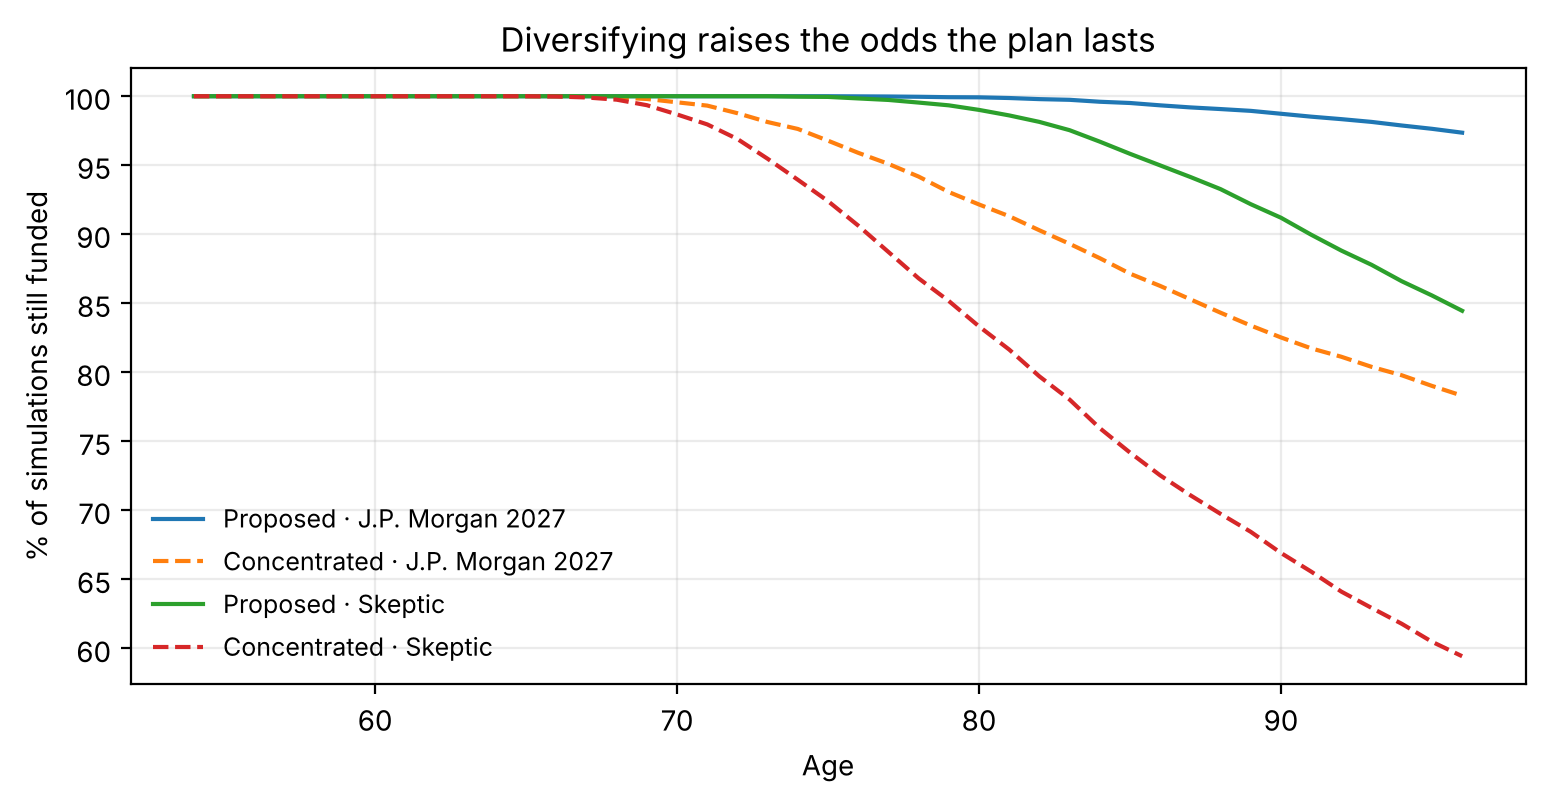

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for k, v in res.items():
    ax.plot(range(54, 97), v * 100, label=k, ls="-" if "Proposed" in k else "--")
ax.set_xlabel("Age"); ax.set_ylabel("% of simulations still funded"); ax.legend(frameon=False, fontsize=9); ax.grid(alpha=.25)
ax.set_title("Diversifying raises the odds the plan lasts"); plt.show()

**Note:** the case study page runs 4,000 simulations in the browser with a different random-number generator, so its percentages can differ from these by about a point.